# Comparateur des programmes retraites (2027) & Audit du plan David Lisnard

Ce carnet interactif analyse de façon **neutre, chiffrée et sourcée** les propositions de réforme des retraites des principaux courants et candidats pour 2027, avec un **focus détaillé sur le projet de David Lisnard (*Nouvelle Énergie*)**.

Tous les calculs s'appuient sur les données officielles les plus fiables interrogées via [`analyse_retraites.py`](./analyse_retraites.py) et [`comparateur_programmes_retraites.py`](./comparateur_programmes_retraites.py) :
- **DREES 2024** (*Comptes de la Protection Sociale* : **406,02 Md€/an** de pensions pour **17,89 M** de retraités) ;
- **DREES EIR / ANCETRE** (distribution des pensions par tranche, âges de départ, carrières complètes) ;
- **Eurostat 2025** (pyramide des âges de la France).


## 1. Chargement des données officielles DREES & Eurostat


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from analyse_retraites import ConnecteurDonneesRetraites
from comparateur_programmes_retraites import (
    ParametresAuditLisnard,
    catalogue_programmes,
    simuler_comparatif_programmes,
    simuler_tranches_lisnard,
    simuler_lisnard_trajectoire_15ans,
    simuler_option_logement_lisnard,
    analyser_assiette_desindexation,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
plt.style.use("seaborn-v0_8-whitegrid")

donnees = ConnecteurDonneesRetraites(refresh_cache=False).charger_tout()
print(f"Données chargées : DREES {donnees.annee_cps} ({donnees.masse_pensions_brut_mde:.2f} Md€/an de pensions) | Eurostat {donnees.annee_eurostat}")


Données chargées : DREES 2024 (406.02 Md€/an de pensions) | Eurostat 2025


## 2. Vue d'ensemble : comment les candidats veulent-ils changer les retraites, et où piochent-ils l'argent ?

On distingue trois grandes familles de propositions :
1. **Basculer fortement vers la capitalisation** (*David Lisnard* à 40 %, *Sarah Knafo / Éric Zemmour* vers 100 %) : l'idée est que l'argent placé sur les marchés financiers rapporte davantage sur 40 ans que la croissance des salaires en répartition. **Le défi** : pendant les 15 à 30 premières années, les cotisations qui partent dans les comptes individuels manquent pour payer les retraités actuels — il faut donc trouver d'autres sources d'argent (désindexation, coupes dans l'État, hausse d'âge).
2. **Allonger la durée de travail + ajouter une petite dose de capitalisation** (*Édouard Philippe* à ~15 %, *Les Républicains* à ~10 %, *Gabriel Attal* par la durée de cotisation) : on demande surtout aux **actifs** de partir plus tard (65 ans ou 45 annuités) pour équilibrer la répartition tout en créant une épargne complémentaire.
3. **Rester à 100 % en répartition et abaisser l'âge de départ** (*RN*, *PS*, *LFI*) : on permet aux actifs de partir plus tôt (60 ou 62 ans) et/ou on relève les petites pensions. Cela augmente la dépense de retraite (+16 à +36 Md€/an à 10 ans), que ces programmes prévoient de financer en puisant soit dans le budget général (économies immigration/UE pour le RN), soit via une hausse de fiscalité sur les grandes entreprises, les hauts patrimoines ou les cotisations (PS, LFI).


,Candidat / Programme,Âge départ,Annuités,Rép. / Capi.,Minimum (€),Où il pioche (financement),Besoin brut t+10a (Md€),Recettes fléchées t+10a (Md€),Solde non couvert t+10a (Md€),Pension actif 22a (éq. auj.),Pension actif 40a (éq. auj.),Taux remp. 22a (%)
0,David Lisnard (Nouvelle Énergie),65,43,60 / 40 %,"1,000 €",Désindexation pensions > 2 000 € + âge à 65 ans + baisse dépenses publiques,+106.5 Md€,21.0 Md€,-85.5 Md€,"3,302 €","2,325 €",128.0 %
1,Édouard Philippe (Horizons),65,45,85 / 15 %,"1,200 €",Âge légal à 65 ans + 45 annuités + abondement PER jeunes actifs,+14.5 Md€,0.0 Md€,-14.5 Md€,"2,344 €","2,065 €",90.9 %
2,Sarah Knafo / É. Zemmour (Reconquête),64,43,0 / 100 %,—,"Plan d'économies publiques (140 Md€ affichés : administration, aides sociales)",+162.4 Md€,80.0 Md€,-82.4 Md€,"3,853 €","2,309 €",149.3 %
3,Les Républicains (LR / B. Retailleau),65,43,90 / 10 %,"1,200 €",Âge légal à 64-65 ans + maîtrise dépense sociale + étage fonds souverain,+17.1 Md€,5.0 Md€,-12.1 Md€,"2,198 €","1,988 €",85.2 %
4,Gabriel Attal (Renaissance),64,43,95 / 5 %,"1,200 €",43 annuités (suppression de l'âge légal rigide) + PER incitatif,+13.5 Md€,5.0 Md€,-8.5 Md€,"1,988 €","1,892 €",77.1 %
5,Marine Le Pen / J. Bardella (RN),62,42,100 / 0 %,"1,200 €",Économies immigration/UE/fraude + natalité et hausses de salaires,+18.0 Md€,15.0 Md€,-3.0 Md€,"1,723 €","1,723 €",66.8 %
6,Parti Socialiste (PS),62,43,100 / 0 %,"1,300 €",Taxation hauts patrimoines/superprofits + niches fiscales + Fonds de réserve (FRR),+16.0 Md€,14.0 Md€,-2.0 Md€,"1,754 €","1,754 €",68.0 %
7,La France Insoumise (LFI),60,40,100 / 0 %,"1,426 €",Hausse cotisations patronales + fin exonérations + taxe revenus financiers,+36.0 Md€,32.0 Md€,-4.0 Md€,"1,558 €","1,558 €",60.4 %


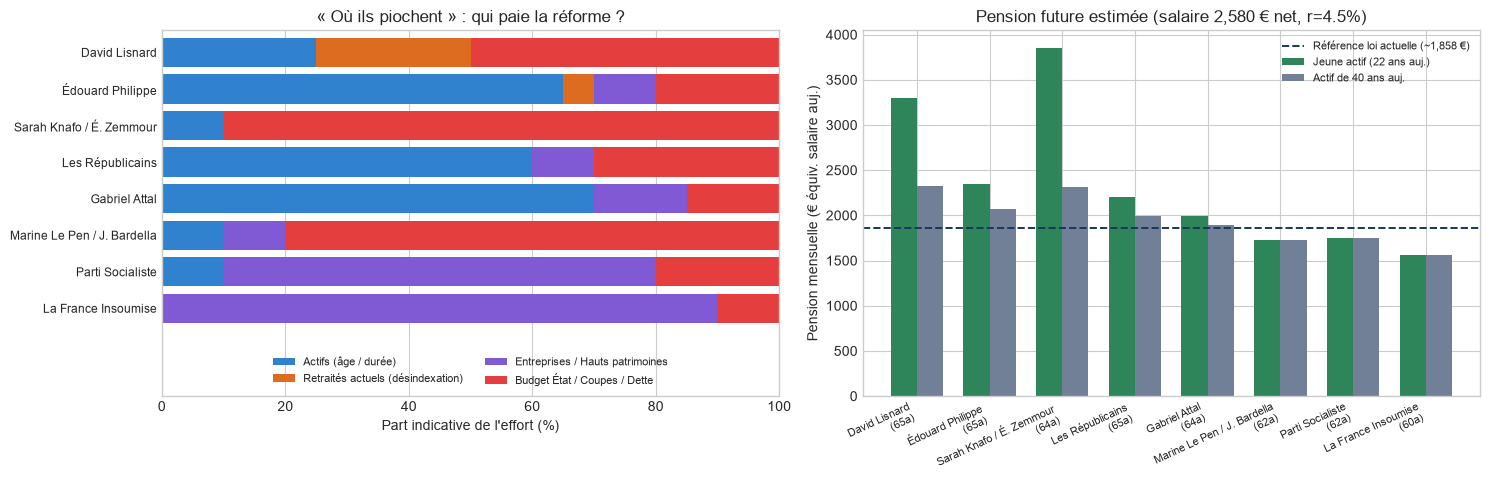

In [2]:
# === PARAMÈTRES COMPARATEUR ===
SALAIRE_NET_REF = 2580.0     # Salaire net mensuel de référence pour comparer les futures pensions (€)
RENDEMENT_REEL_CAPI = 4.5    # Hypothèse de rendement réel net d'inflation pour les programmes capitalisés (%)

programmes = catalogue_programmes(donnees)
df_comp = simuler_comparatif_programmes(
    donnees,
    programmes,
    salaire_net_ref=SALAIRE_NET_REF,
    rendement_reel_pct=RENDEMENT_REEL_CAPI,
)

display(
    df_comp.style.format(
        {
            "Annuités": "{:.0f}",
            "Minimum (€)": "{:,.0f} €",
            "Besoin brut t+10a (Md€)": "{:+.1f} Md€",
            "Recettes fléchées t+10a (Md€)": "{:.1f} Md€",
            "Solde non couvert t+10a (Md€)": "{:+.1f} Md€",
            "Pension actif 22a (éq. auj.)": "{:,.0f} €",
            "Pension actif 40a (éq. auj.)": "{:,.0f} €",
            "Taux remp. 22a (%)": "{:.1f} %",
        },
        na_rep="—",
    )
)

# Graphique comparatif : Qui finance (où ils piochent) & Futures pensions
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.0))
noms_courts = [p.candidat_parti.split(" (")[0] for p in programmes]
y_p = np.arange(len(programmes))

actifs = np.array([p.effort_actifs_age_pct for p in programmes])
retraites = np.array([p.effort_retraites_actuels_pct for p in programmes])
entrep = np.array([p.effort_entreprises_impots_pct for p in programmes])
budget = np.array([p.effort_budget_etat_dette_pct for p in programmes])

ax1.barh(y_p, actifs, color="#3182ce", label="Actifs (âge / durée)")
ax1.barh(y_p, retraites, left=actifs, color="#dd6b20", label="Retraités actuels (désindexation)")
ax1.barh(y_p, entrep, left=actifs + retraites, color="#805ad5", label="Entreprises / Hauts patrimoines")
ax1.barh(y_p, budget, left=actifs + retraites + entrep, color="#e53e3e", label="Budget État / Coupes / Dette")
ax1.set_yticks(y_p)
ax1.set_yticklabels(noms_courts, fontsize=8.5)
ax1.set_ylim(len(programmes) + 1.4, -0.6)
ax1.set_xlim(0, 100)
ax1.set_xlabel("Part indicative de l'effort (%)")
ax1.set_title("« Où ils piochent » : qui paie la réforme ?")
ax1.legend(fontsize=7.8, loc="lower center", ncol=2, framealpha=0.95)

w_b = 0.36
ax2.bar(y_p - w_b / 2, df_comp["Pension actif 22a (éq. auj.)"], width=w_b, color="#2f855a", label="Jeune actif (22 ans auj.)")
ax2.bar(y_p + w_b / 2, df_comp["Pension actif 40a (éq. auj.)"], width=w_b, color="#718096", label="Actif de 40 ans auj.")
ax2.axhline(SALAIRE_NET_REF * 0.72, color="#1a365d", linestyle="--", lw=1.4, label=f"Référence loi actuelle (~{SALAIRE_NET_REF*0.72:,.0f} €)")
ax2.set_xticks(y_p)
ax2.set_xticklabels([f"{n}\n({a}a)" for n, a in zip(noms_courts, df_comp["Âge départ"])], rotation=25, ha="right", fontsize=8)
ax2.set_ylabel("Pension mensuelle (€ équiv. salaire auj.)")
ax2.set_title(f"Pension future estimée (salaire {SALAIRE_NET_REF:,.0f} € net, r={RENDEMENT_REEL_CAPI:.1f}%)")
ax2.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 3. Focus & Audit détaillé : transition sur 15 ans du plan David Lisnard (0 % → 40 % de capitalisation)

### Ce que propose David Lisnard (*Nouvelle Énergie*)
Le projet vise à transformer le système de retraite français en un modèle hybride **60 % répartition / 40 % capitalisation** :
- **Âge légal fixé à 65 ans** (+1 an par rapport aux 64 ans de la réforme 2023).
- **Un socle universel de 1 000 €/mois dès 65 ans** garanti par répartition (financé par 60 % des cotisations).
- **40 % des cotisations basculées en capitalisation individuelle** sur un compte personnel (soit **116 Md€/an** sur le socle contributif direct, ou **162,4 Md€/an** sur la totalité des 406 Md€ de pensions DREES).
- **Durée de transition demandée : 15 ans** (montée progressive de $+2,67$ points de capitalisation par an, soit $+7,73$ Md€ de cotisations basculées par an).
- **Gestion de l'épargne** : fonds souverain public par défaut (investi en partie dans les entreprises françaises) ou choix d'un gestionnaire privé certifié.
- **Option résidence principale** : déblocage possible de jusqu'à **30 % de son capital** pour l'apport d'un premier achat immobilier.

---

### D'où pioche-t-il l'argent année par année pour financer la transition ?
Pendant les 15 ans, les cotisations des actifs qui partent vers les comptes de capitalisation créent un besoin de trésorerie immédiat (« coût de transition » ou double charge) : il faut continuer à verser l'intégralité des pensions aux retraités actuels. David Lisnard mobilise 3 ressources internes, complétées par les finances publiques :

1. **Désindexation des pensions > 2 000 € net/mois** :
   - Sur les données DREES 2024, cette mesure touche **5,78 millions de retraités** (32,3 % du total) et porte sur **218,1 Md€ brut/an** (53,7 % de toutes les pensions).
   - En gelant ces pensions nominales face à une inflation de 1,8 %/an, l'économie brute monte de **3,8 Md€** en An 1 à **17,2 Md€** en An 5, **30,3 Md€** en An 10 et **40,1 Md€/an** en An 15.
2. **Recul de l'âge légal à 65 ans (net du socle 1 000 €)** :
   - Reculer l'âge légal à 65 ans (montée en charge progressive sur 4 ans) génère **+10,5 Md€/an** d'économies en régime plein.
   - Déduction faite du relèvement du minimum à 1 000 €/mois dès 65 ans (~1,2 Md€ brut sur carrière complète), le gain net s'établit à **+1,4 Md€** en An 1, **+4,1 Md€** en An 2, **+6,7 Md€** en An 3 et **+9,3 Md€/an** stables de l'An 4 à l'An 15.
3. **Économies acquises sur le socle par répartition (renouvellement du stock)** :
   - À mesure que les retraités actuels décèdent et que de nouvelles générations liquident avec une pension de répartition réduite à 60 % (complétée par leur propre capitalisation), les dépenses de répartition diminuent chaque année.
   - Cette économie est quasi-nulle au début (**0,01 Md€** en An 1), mais s'accélère : **0,4 Md€** en An 5, **2,4 Md€** en An 10 et **7,1 Md€/an** en An 15.
4. **Écart résiduel / Besoin de financement du budget de l'État** :
   - Le flux versé en capitalisation dépasse les ressources propres internes : l'écart s'élève à **2,5 Md€** en An 1, **11,8 Md€** en An 5, **35,3 Md€** en An 10 et **59,5 Md€** en An 15.
   - Sur l'ensemble des 15 ans, le besoin cumulé de financement s'élève à **408,9 Md€** (soit une moyenne de **27,3 Md€/an**).
   - David Lisnard justifie cette couverture par son plan global d'économies de **100 à 120 Md€ sur la dépense publique** (réduction des effectifs administratifs, suppression d'agences d'État, réformes de structure).


=== 1. ASSIETTE DE LA DÉSINDEXATION > 2 000 € (DREES 2024) ===
  - Retraités touchés : 5.78 millions (32.3 % des retraités)
  - Masse brute de leurs pensions : 218.1 Md€/an (53.7 % de toutes les pensions)

=== 2. TRAJECTOIRE ANNÉE PAR ANNÉE (1 À 15 ANS) : 0 % → 40 % DE CAPITALISATION ===


,Année,Tranche,% Capitalisation,Flux Capi (cible 116 Md€),Équiv. 40% total DREES,Désindexation > seuil,Solde 65 ans - Min 1000€,Écon. socle répartition,Total ressources propres,Besoin annuel budget État,Besoin cumulé budget État,Taux couverture propre (%)
0,1,T1,2.7 %,7.7 Md€,10.8 Md€,3.8 Md€,+1.4 Md€,0.0 Md€,5.2 Md€,+2.5 Md€,+2.5 Md€,67.8 %
1,2,T2,5.3 %,15.5 Md€,21.7 Md€,7.4 Md€,+4.1 Md€,0.0 Md€,11.5 Md€,+3.9 Md€,+6.4 Md€,74.5 %
2,3,T2,8.0 %,23.2 Md€,32.5 Md€,10.9 Md€,+6.7 Md€,0.1 Md€,17.7 Md€,+5.5 Md€,+12.0 Md€,76.1 %
3,4,T3,10.7 %,30.9 Md€,43.3 Md€,14.1 Md€,+9.3 Md€,0.2 Md€,23.7 Md€,+7.3 Md€,+19.3 Md€,76.5 %
4,5,T3,13.3 %,38.7 Md€,54.1 Md€,17.2 Md€,+9.3 Md€,0.4 Md€,26.9 Md€,+11.8 Md€,+31.0 Md€,69.6 %
5,6,T4,16.0 %,46.4 Md€,65.0 Md€,20.1 Md€,+9.3 Md€,0.6 Md€,30.1 Md€,+16.3 Md€,+47.3 Md€,64.8 %
6,7,T4,18.7 %,54.1 Md€,75.8 Md€,22.9 Md€,+9.3 Md€,1.0 Md€,33.1 Md€,+21.0 Md€,+68.3 Md€,61.2 %
7,8,T5,21.3 %,61.9 Md€,86.6 Md€,25.5 Md€,+9.3 Md€,1.4 Md€,36.2 Md€,+25.7 Md€,+94.1 Md€,58.4 %
8,9,T5,24.0 %,69.6 Md€,97.4 Md€,28.0 Md€,+9.3 Md€,1.8 Md€,39.1 Md€,+30.5 Md€,+124.5 Md€,56.2 %
9,10,T6,26.7 %,77.3 Md€,108.3 Md€,30.3 Md€,+9.3 Md€,2.4 Md€,42.0 Md€,+35.3 Md€,+159.8 Md€,54.4 %


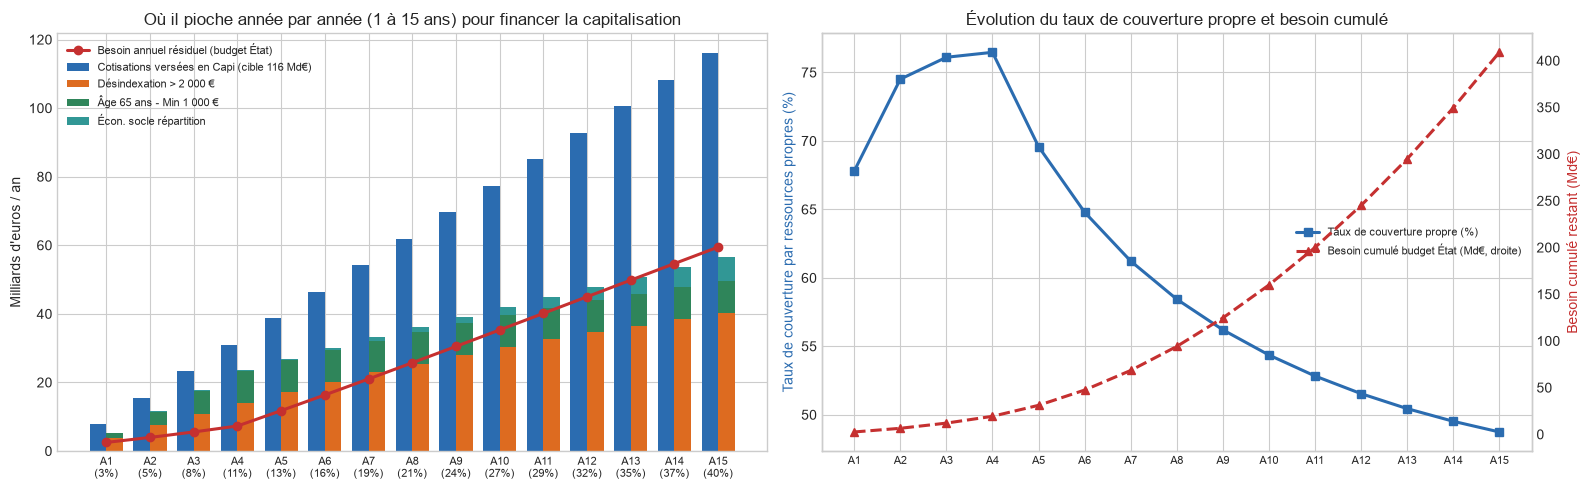


=== 3. IMPACT DE L'OPTION RÉSIDENCE PRINCIPALE (RETRAIT DE 30 % À 35 ANS) ===


,Profil salarial,Apport débloqué à 35 ans (€),Capital à 65 ans sans retrait,Pension 65a SANS retrait (éq. auj.),Pension 65a AVEC retrait 30% (éq. auj.),Baisse rente à 65a (€/mois)
0,SMIC (1 426 € net),"14,981 €","236,502 €","1,983 €","1,783 €",-200 €
1,Salaire médian (2 180 € net),"22,902 €","361,553 €","3,032 €","2,726 €",-305 €
2,Salaire moyen (2 580 € net),"27,104 €","427,894 €","3,588 €","3,227 €",-361 €
3,Cadre (4 200 € net),"44,123 €","696,571 €","5,841 €","5,253 €",-588 €


In [3]:
# === PARAMÈTRES DE LA TRANSITION SUR 15 ANS ===
DUREE_TRANSITION_ANS = 15          # Durée de transition demandée (15 ans)
SEUIL_DESINDEXATION_NET = 2000.0   # Seuil net à partir duquel les pensions sont gelées (€/mois)
INFLATION_PCT = 1.8                # Hypothèse d'inflation annuelle (%)
GEL_COMPLET = True                 # True = gel total avec plancher à 2000€ | False = gel marginal (>2000€)
MIN_CARRIERE_COMPLETE = True       # True = minimum 1 000 € réservé aux carrières complètes
RETRAIT_LOGEMENT_PCT = 30.0        # % de capital débloqué pour la résidence principale
AGE_RETRAIT_LOGEMENT = 35          # Âge du déblocage immobilier

params_lisnard = ParametresAuditLisnard(
    duree_transition_ans=DUREE_TRANSITION_ANS,
    seuil_desindexation_net_eur=SEUIL_DESINDEXATION_NET,
    inflation_annuelle_pct=INFLATION_PCT,
    gel_complet_au_dessus_seuil=GEL_COMPLET,
    min_carriere_complete_seule=MIN_CARRIERE_COMPLETE,
    rendement_reel_capi_pct=RENDEMENT_REEL_CAPI,
    retrait_immobilier_pct=RETRAIT_LOGEMENT_PCT,
    age_retrait_immobilier=AGE_RETRAIT_LOGEMENT,
)

# 1. Calcul de la trajectoire année par année sur 15 ans
df_15 = simuler_lisnard_trajectoire_15ans(donnees, params_lisnard, duree_annees=DUREE_TRANSITION_ANS)
asst = analyser_assiette_desindexation(donnees, seuil_net=SEUIL_DESINDEXATION_NET, inflation_pct=INFLATION_PCT)

print("=== 1. ASSIETTE DE LA DÉSINDEXATION > 2 000 € (DREES 2024) ===")
print(f"  - Retraités touchés : {asst['eff_touches_k']/1000:.2f} millions ({asst['pct_retraites_touches']:.1f} % des retraités)")
print(f"  - Masse brute de leurs pensions : {asst['masse_pensions_sup_brut_mde']:.1f} Md€/an ({asst['pct_masse_concernee']:.1f} % de toutes les pensions)")

print(f"\n=== 2. TRAJECTOIRE ANNÉE PAR ANNÉE (1 À {DUREE_TRANSITION_ANS} ANS) : 0 % → 40 % DE CAPITALISATION ===")
display(
    df_15.style.format(
        {
            "% Capitalisation": "{:.1f} %",
            "Flux Capi (cible 116 Md€)": "{:.1f} Md€",
            "Équiv. 40% total DREES": "{:.1f} Md€",
            "Désindexation > seuil": "{:.1f} Md€",
            "Solde 65 ans - Min 1000€": "{:+.1f} Md€",
            "Écon. socle répartition": "{:.1f} Md€",
            "Total ressources propres": "{:.1f} Md€",
            "Besoin annuel budget État": "{:+.1f} Md€",
            "Besoin cumulé budget État": "{:+.1f} Md€",
            "Taux couverture propre (%)": "{:.1f} %",
        }
    )
)

# Graphique de la transition 15 ans
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5.0))
x = np.arange(len(df_15))
w = 0.38

# Panneau 1 : Flux de cotisations basculées vs Recettes propres empilées
ax1.bar(x - w / 2, df_15["Flux Capi (cible 116 Md€)"], width=w, color="#2b6cb0", label="Cotisations versées en Capi (cible 116 Md€)")
r_des = df_15["Désindexation > seuil"].values
r_65 = df_15["Solde 65 ans - Min 1000€"].values
r_ec = df_15["Écon. socle répartition"].values

ax1.bar(x + w / 2, r_des, width=w, color="#dd6b20", label="Désindexation > 2 000 €")
ax1.bar(x + w / 2, r_65, bottom=r_des, width=w, color="#2f855a", label="Âge 65 ans - Min 1 000 €")
ax1.bar(x + w / 2, r_ec, bottom=r_des + r_65, width=w, color="#319795", label="Écon. socle répartition")
ax1.plot(x, df_15["Besoin annuel budget État"], color="#c53030", marker="o", lw=2.2, label="Besoin annuel résiduel (budget État)")

ax1.set_xticks(x)
ax1.set_xticklabels([f"A{int(a)}\n({p:.0f}%)" for a, p in zip(df_15["Année"], df_15["% Capitalisation"])], fontsize=8)
ax1.set_ylabel("Milliards d'euros / an")
ax1.set_title("Où il pioche année par année (1 à 15 ans) pour financer la capitalisation")
ax1.legend(fontsize=7.8, loc="upper left")

# Panneau 2 : Taux de couverture & Besoin cumulé
ax2_twin = ax2.twinx()
p1 = ax2.plot(x, df_15["Taux couverture propre (%)"], color="#2b6cb0", marker="s", lw=2.2, label="Taux de couverture propre (%)")
p2 = ax2_twin.plot(x, df_15["Besoin cumulé budget État"], color="#c53030", marker="^", lw=2.2, linestyle="--", label="Besoin cumulé budget État (Md€, droite)")

ax2.set_xticks(x)
ax2.set_xticklabels([f"A{int(a)}" for a in df_15["Année"]], fontsize=8)
ax2.set_ylabel("Taux de couverture par ressources propres (%)", color="#2b6cb0")
ax2_twin.set_ylabel("Besoin cumulé restant (Md€)", color="#c53030")
ax2_twin.grid(False)
ax2.set_title("Évolution du taux de couverture propre et besoin cumulé")

lns = p1 + p2
labs = [l.get_label() for l in lns]
ax2.legend(lns, labs, loc="center right", fontsize=8)

plt.tight_layout()
plt.show()

# 2. Option résidence principale
print("\n=== 3. IMPACT DE L'OPTION RÉSIDENCE PRINCIPALE (RETRAIT DE 30 % À 35 ANS) ===")
df_immo = simuler_option_logement_lisnard(donnees, params_lisnard)
col_app = [c for c in df_immo.columns if "Apport" in c][0]
display(
    df_immo.style.format(
        {
            col_app: "{:,.0f} €",
            "Capital à 65 ans sans retrait": "{:,.0f} €",
            "Pension 65a SANS retrait (éq. auj.)": "{:,.0f} €",
            "Pension 65a AVEC retrait 30% (éq. auj.)": "{:,.0f} €",
            "Baisse rente à 65a (€/mois)": "{:+,.0f} €",
        }
    )
)


## 4. Synthèse & Bilan d'audit : ce qu'il récupère d'où et cohérence du plan Lisnard

En croisant la trajectoire sur 15 ans avec les données réelles de la DREES (406 Md€ de pensions, 17,89 M de retraités), voici les conclusions objectives de l'audit :

### 1. Progression de 0 % à 40 % de capitalisation sur 15 ans
- **Chaque année, la part capitalisée augmente de $+2,67$ points de pourcentage** : $2,7\ %$ en An 1, $13,3\ %$ en An 5, $26,7\ %$ en An 10, pour atteindre les $40,0\ %$ en An 15.
- **Le flux annuel de cotisations versé en capitalisation** augmente de **$+7,73$ Md€ par an** pour atteindre **116 Md€/an** au bout de 15 ans (ou **162,4 Md€/an** si calculé sur l'intégralité des 406 Md€ de la masse DREES).

### 2. D'où récupère-t-il l'argent exactement ?
1. **La désindexation des pensions > 2 000 € net/mois est le premier pilier financier interne** :
   - Elle rapporte **3,8 Md€** dès l'An 1, **17,2 Md€** en An 5, **30,3 Md€** en An 10 et **40,1 Md€/an** en An 15.
   - *Impact sur les retraités* : au bout de 15 ans à 1,8 % d'inflation annuelle, une pension gelée autour de 2 800 € net perd environ **23,5 %** de son pouvoir d'achat réel.
2. **Le recul de l'âge légal à 65 ans net du minimum garanti à 1 000 €** :
   - Montée en charge sur 4 ans : dégage un gain net stable de **+9,3 Md€/an** à partir de l'An 4 (10,5 Md€ d'économies brutes sur la dépense de retraite moins 1,2 Md€ de coût pour le plancher à 1 000 € sur carrières complètes).
3. **Les économies de socle par répartition** :
   - Elles s'installent lentement au rythme du renouvellement des cohortes : **0,01 Md€** en An 1, **0,4 Md€** en An 5, **2,4 Md€** en An 10 et **7,1 Md€/an** en An 15.

### 3. Quel est l'écart résiduel et comment est-il comblé ?
- **Dans les 4 premières années**, le plan est largement autofinancé à **68 % – 76 %** par ses ressources propres : le besoin de financement budgétaire annuel reste très modéré (de **2,5 Md€** en An 1 à **7,3 Md€** en An 4).
- **À partir de l'An 5**, le flux versé en capitalisation accélère plus vite que la montée des recettes internes. L'écart annuel à combler par le budget de l'État monte à **11,8 Md€** (An 5), **35,3 Md€** (An 10) et culmine à **59,5 Md€** en An 15.
- **Au total sur les 15 ans**, le besoin de transition cumulé s'élève à **408,9 Md€** (soit une moyenne de **27,3 Md€ par an**).
- **Cohérence d'ensemble** : ce besoin annuel moyen (~27 Md€/an) est compatible avec l'objectif de **100 à 120 Md€ de réductions de dépenses publiques** affiché par David Lisnard sur le budget de l'État et ses agences. Cependant, la réussite de la réforme dépend de la capacité effective du gouvernement à maintenir ces coupes budgétaires de manière pérenne pendant les 15 années de transition.
